# Mouse-arm extras — replication, ablation, panel dependence, markers, spatial

**What this is.** The mouse/XMens analyses that `hammoud_atlas_mapping_ALL.ipynb` §3.4 listed as
**never run**. They were run on 2026-09-01 at the user's request (reversing the earlier
leave-un-run decision) by `fib_mapping/run_mapping_mouse_extras.py`, writing to the NEW directory
`fib_centroid_results_mouse_extras/`. The finished directories `fib_centroid_results/` and
`fib_centroid_results_mouse/` were inputs only and are unchanged, as is the combined notebook.

Same standard as the combined notebook: every headline number in prose has a `verify()` beneath it
recomputing it from the source file; the notebook ends with `check_summary()`; target 0 MISMATCH.

## 0. Setup, self-check helper, and the input manifest

In [1]:
import json, os, re, sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

HAM  = Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud")
MOUT = HAM / "fib_centroid_results_mouse"          # finished 2026-08-30, read-only
XOUT = HAM / "fib_centroid_results_mouse_extras"   # NEW, written 2026-09-01
sys.path.insert(0, str(HAM / "fib_mapping"))
from hammoud_fib_mapping import FIB_SUBTYPES, SHORT   # constants only; no computation

# ---- the house self-check helper, copied verbatim from notebooks/verify/ ----
_checks = []
def verify(label, got, expected, tol=0.02, note=""):
    """Recompute vs recorded. Prints PASS/MISMATCH and accumulates a summary."""
    try:
        ok = (abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
              if expected is not None else None)
    except (TypeError, ValueError):
        ok = (got == expected)
    tag = "PASS " if ok else ("MISMATCH" if ok is False else "n/a  ")
    _checks.append((label, got, expected, tag))
    print(f"[{tag}] {label}: recomputed={got}  recorded={expected}" + (f"   ({note})" if note else ""))
    return ok

def check_summary():
    d = pd.DataFrame(_checks, columns=["claim","recomputed","recorded","status"])
    n_bad = int((d.status.str.strip()=="MISMATCH").sum())
    print(f"\n{len(d)} checks | {n_bad} MISMATCH")
    return d

CROSSWALK = {   # short code (results CSVs) -> canonical name (h5ad cell_subtype / driver JSON)
    "dec1":  "decidual_boundary",
    "dec2":  "decidual_proliferative",
    "dec3":  "decidual_mature",
    "decAp": "decidual_apoptotic",
    "eFib1": "efib_outer",
    "eFib2": "efib_middle",
    "eFib2i":"efib_middle_induced",
    "eFib3": "efib_subluminal",
    "eFibP": "efib_proliferative",
}
canon = lambda c: CROSSWALK.get(str(c), str(c))

In [2]:
INPUTS = {}
for name in [
    "cluster_centroids_mouse.parquet", "cluster_sizes_mouse.csv",
    "matrix_contrastive_cosine_recheck.csv",
    "replication_per_sample_mouse.csv", "replication_per_timepoint_mouse.csv",
    "replication_consistency_mouse.csv",
    "robustness_marker_ablation_mouse.csv",
    "matrix_contrastive_cosine_vpanelA.csv", "matrix_contrastive_cosine_vpanelB.csv",
    "gene_bootstrap_mouse_vpanel.csv", "heldout_mouse_vpanel.csv",
    "marker_sets_mouse.csv", "marker_panel_detectability_mouse.csv",
    "program_detectability_mouse.csv", "dotplot_mouse_published_markers.png",
    "per_cell_subtype_scores_mouse.csv", "score_by_cluster_mouse.csv",
    "meta_mouse_extras.json",
]:
    INPUTS[f"extras/{name}"] = XOUT / name
for name in [
    "matrix_contrastive_cosine.csv", "gene_bootstrap_mouse.csv", "heldout_mouse.csv",
    "TABLE_correspondence_mouse_by_query.csv", "hammoud_gene_drivers_v5.json", "meta_mouse.json",
]:
    INPUTS[f"finished/{name}"] = MOUT / name

rows = []
for label, p in INPUTS.items():
    ex = p.exists()
    st = p.stat() if ex else None
    rows.append({"input": label, "exists": ex,
                 "mtime": pd.Timestamp(st.st_mtime, unit="s").strftime("%Y-%m-%d %H:%M") if ex else "-",
                 "size": st.st_size if ex else 0})
manifest = pd.DataFrame(rows)
display(manifest)
verify("all input files present", int((~manifest["exists"]).sum()), 0, tol=0)

,input,exists,mtime,size
0,extras/cluster_centroids_mouse.parquet,True,2026-09-01 19:54,874319
1,extras/cluster_sizes_mouse.csv,True,2026-09-01 19:54,99
2,extras/matrix_contrastive_cosine_recheck.csv,True,2026-09-01 19:54,8066
3,extras/replication_per_sample_mouse.csv,True,2026-09-01 19:54,4597
4,extras/replication_per_timepoint_mouse.csv,True,2026-09-01 19:54,2870
5,extras/replication_consistency_mouse.csv,True,2026-09-01 19:54,286
6,extras/robustness_marker_ablation_mouse.csv,True,2026-09-01 19:54,2803
7,extras/matrix_contrastive_cosine_vpanelA.csv,True,2026-09-01 19:54,1273
8,extras/matrix_contrastive_cosine_vpanelB.csv,True,2026-09-01 19:54,1272
9,extras/gene_bootstrap_mouse_vpanel.csv,True,2026-09-01 19:54,523


[PASS ] all input files present: recomputed=0  recorded=0


True

## 1. Provenance

The extras run used the **deliverables** copy of the XMens object (netscratch is purgeable), the
same Ensembl 116 strict one-to-one ortholog policy, and the same curated `fine_refined` groups as
the finished mouse run. Because the mouse arm never clustered, there is **no resolution sweep here
— N/A by design**. (The HUMAN arm did sweep leiden 0.3–2.0; see the combined notebook §2.1.)

As a free provenance check, the extras job recomputed the all-39 contrastive-cosine matrix from the
deliverables object and diffed it against the finished run's stored matrix (which was computed from
the netscratch copy). Agreement means the finished mouse results reproduce exactly from the
purge-safe copy of the data.

In [3]:
meta_x = json.loads((XOUT / "meta_mouse_extras.json").read_text())
meta_0 = json.loads((MOUT / "meta_mouse.json").read_text())
print(json.dumps(meta_x, indent=2))
verify("extras object size", int(meta_x["n_cells"]), 43197, tol=0)
verify("shared ortholog panel matches the finished run", int(meta_x["panel_genes"]), int(meta_0["panel_genes"]), tol=0)
verify("atlas genes translated matches the finished run", int(meta_x["atlas_genes_translated"]), int(meta_0["atlas_genes_translated"]), tol=0)

M_re = pd.read_csv(XOUT / "matrix_contrastive_cosine_recheck.csv", index_col=0)
M_0  = pd.read_csv(MOUT / "matrix_contrastive_cosine.csv", index_col=0)
maxdiff = float((M_re - M_0.loc[M_re.index, M_re.columns]).abs().max().max())
print(f"max |diff|, recomputed (deliverables) vs finished (netscratch): {maxdiff:.3e}")
verify("finished mouse matrix reproduces from the deliverables object (max |diff| vs 0)",
       maxdiff, 0, tol=1e-12, note="observed 9.89e-17 in the job log")

{
  "object": "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/deliverables/2026_08_28_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad",
  "cluster_key": "fine_refined",
  "n_cells": 43197,
  "panel_genes": 15606,
  "atlas_genes_translated": 15681,
  "vpanelA_genes": 3000,
  "vpanelB_genes": 2509,
  "provenance_max_abs_diff_vs_finished_run": 9.8879238130678e-17,
  "ortholog_policy": "Ensembl116 strict one2one, symbol-unique both ways",
  "replication_cols": "6 FIB_SUBTYPES (6-column centring)",
  "seed": 0,
  "run_date": "2026-09-01 15:55:13.159873"
}
[PASS ] extras object size: recomputed=43197  recorded=43197
[PASS ] shared ortholog panel matches the finished run: recomputed=15606  recorded=15606
[PASS ] atlas genes translated matches the finished run: recomputed=15681  recorded=15681
max |diff|, recomputed (deliverables) vs finished (netscratch): 0.000e+00
[PASS ] finished mouse matrix reproduces from the deliverables object (max |diff| vs 0): recomputed=0.0  recorded=0   (observed 9.8

True

## 2. Replication — per section and per timepoint

The mapping recomputed from scratch inside each of the 9 sections and each of the 6 timepoints,
with the six fibroblast subtypes as columns (6-column centring, parallel to the human §2.5).

**Critical caveat, unlike the human arm:** the mouse timepoints are an **induction time course**
(uninduced → 1_dpi_early → 1_dpi_late → 2_dpi → 3_dpi → 4_dpi_bleeding) and cluster composition
shifts massively along it — the decidual clusters barely exist in uninduced sections and the outer
fibroblasts dominate them. Cross-timepoint disagreement can therefore be **biology, not failed
replication**. The honest replication axis is the three **within-timepoint section pairs**:
uninduced_mck8a/b, 1_dpi_late_mck12a/b, 3_dpi_mck10a/b.

In [4]:
per_sample = pd.read_csv(XOUT / "replication_per_sample_mouse.csv")
per_tp     = pd.read_csv(XOUT / "replication_per_timepoint_mouse.csv")
consistency = pd.read_csv(XOUT / "replication_consistency_mouse.csv")

pivot = per_sample.pivot(index="subtype", columns="sample", values="best_query")
pivot_c = pivot.applymap(canon)
pivot_c.index = [SHORT.get(i, i) for i in pivot_c.index]
display(pivot_c)
tp_pivot = per_tp.pivot(index="subtype", columns="timepoint", values="best_query").applymap(canon)
tp_pivot.index = [SHORT.get(i, i) for i in tp_pivot.index]
display(tp_pivot)

rec_cons = per_sample.groupby("subtype")["best_query"].agg(
    modal=lambda s: s.value_counts().index[0],
    agreement=lambda s: s.value_counts(normalize=True).iloc[0],
    n_samples="size").reset_index()
merged = rec_cons.merge(consistency, on="subtype", suffixes=("_re", ""))
ok = int(((merged["modal_re"].astype(str) == merged["modal"].astype(str))
          & (np.isclose(merged["agreement_re"], merged["agreement"]))
          & (merged["n_samples_re"] == merged["n_samples"])).sum())
verify("stored consistency table reproduces from per-sample results (6 subtypes)", ok, 6, tol=0)
cons_ix = consistency.set_index("subtype")
verify("Stro-7 -> efib_outer in ALL 9 sections", float(cons_ix.loc["Stro-7_C7 Fibroblast", "agreement"]), 1.0, tol=0)
verify("replication ran over 9 sections", int(cons_ix.loc["Stro-7_C7 Fibroblast", "n_samples"]), 9, tol=0)
display(consistency.round(3))

sample,1_dpi_early_mck1,1_dpi_late_mck12a,1_dpi_late_mck12b,2_dpi_mck15,3_dpi_mck10a,3_dpi_mck10b,4_dpi_bleeding_mck11a,uninduced_mck8a,uninduced_mck8b
Stro-10 dS3,efib_middle_induced,efib_middle_induced,efib_middle_induced,efib_middle_induced,efib_middle_induced,efib_middle_induced,decidual_boundary,efib_subluminal,efib_subluminal
Stro-11 progenitor,efib_proliferative,efib_proliferative,efib_proliferative,decidual_proliferative,decidual_proliferative,efib_proliferative,decidual_apoptotic,efib_proliferative,efib_proliferative
Stro-5 RUNX3+,efib_subluminal,decidual_mature,decidual_mature,decidual_mature,decidual_mature,decidual_mature,decidual_mature,efib_middle,efib_middle
Stro-7 C7,efib_outer,efib_outer,efib_outer,efib_outer,efib_outer,efib_outer,efib_outer,efib_outer,efib_outer
Stro-8 dS1,efib_subluminal,decidual_mature,decidual_mature,decidual_mature,decidual_mature,efib_subluminal,decidual_mature,efib_middle,efib_subluminal
Stro-9 dS2,efib_subluminal,decidual_mature,decidual_mature,decidual_mature,efib_subluminal,efib_subluminal,decidual_mature,efib_middle,efib_middle


timepoint,1_dpi_early,1_dpi_late,2_dpi,3_dpi,4_dpi_bleeding,uninduced
Stro-10 dS3,efib_middle_induced,efib_middle_induced,efib_middle_induced,efib_middle_induced,decidual_boundary,efib_subluminal
Stro-11 progenitor,efib_proliferative,efib_proliferative,decidual_proliferative,efib_proliferative,decidual_apoptotic,efib_proliferative
Stro-5 RUNX3+,efib_subluminal,decidual_mature,decidual_mature,decidual_mature,decidual_mature,efib_subluminal
Stro-7 C7,efib_outer,efib_outer,efib_outer,efib_outer,efib_outer,efib_outer
Stro-8 dS1,efib_subluminal,decidual_mature,decidual_mature,decidual_apoptotic,decidual_mature,efib_subluminal
Stro-9 dS2,efib_subluminal,decidual_mature,decidual_mature,efib_subluminal,decidual_mature,efib_subluminal


[PASS ] stored consistency table reproduces from per-sample results (6 subtypes): recomputed=6  recorded=6
[PASS ] Stro-7 -> efib_outer in ALL 9 sections: recomputed=1.0  recorded=1.0
[PASS ] replication ran over 9 sections: recomputed=9  recorded=9


,subtype,modal,agreement,n_samples
0,Stro-10_dS3,eFib2i,0.667,9
1,Stro-11_Stromal progenitor,eFibP,0.667,9
2,Stro-5_RUNX3+ Fibroblast,dec3,0.667,9
3,Stro-7_C7 Fibroblast,eFib1,1.000,9
4,Stro-8_dS1,dec3,0.556,9
5,Stro-9_dS2,dec3,0.444,9


### Within-timepoint section pairs — the honest replication axis

For each subtype and each of the three section pairs: does the same query cluster win in both
sections of the pair?

Reading guide, verified below: **Stro-7 agrees in 3/3 pairs** (and 9/9 sections outright).
**Stro-10 agrees in 3/3 pairs while switching cluster across timepoints** (efib_subluminal when
uninduced, efib_middle_induced once induced) — that switch is induction biology, exactly the caveat
above, not instability. **Stro-8 agrees in only 1/3 pairs** — genuinely unstable per-section.
Stro-5's per-section winner is decidual_mature at weak scores; with its markers detected in only
2.7% of cells (§5), treat that as noise, not a match.

In [5]:
PAIRS = {"uninduced": ("uninduced_mck8a", "uninduced_mck8b"),
         "1_dpi_late": ("1_dpi_late_mck12a", "1_dpi_late_mck12b"),
         "3_dpi": ("3_dpi_mck10a", "3_dpi_mck10b")}
pair_rows = []
for s in pivot.index:
    row = {"subtype": SHORT.get(s, s)}
    for pname, (a_, b_) in PAIRS.items():
        va = canon(pivot.loc[s, a_]) if a_ in pivot.columns and pd.notna(pivot.loc[s, a_]) else None
        vb = canon(pivot.loc[s, b_]) if b_ in pivot.columns and pd.notna(pivot.loc[s, b_]) else None
        row[pname] = f"{va} == {vb}" if va == vb and va is not None else f"{va} != {vb}"
        row[pname + "_agree"] = bool(va == vb and va is not None)
    pair_rows.append(row)
pair_tbl = pd.DataFrame(pair_rows).set_index("subtype")
display(pair_tbl[[c for c in pair_tbl.columns if not c.endswith("_agree")]])
agree_cols = [c for c in pair_tbl.columns if c.endswith("_agree")]
pair_agree = pair_tbl[agree_cols].sum(axis=1).astype(int)
print("pairs agreeing (of 3) per subtype:"); print(pair_agree.to_string())
verify("Stro-7: within-pair agreement (of 3 pairs)", int(pair_agree["Stro-7 C7"]), 3, tol=0)
verify("Stro-11: within-pair agreement (of 3 pairs)", int(pair_agree["Stro-11 progenitor"]), 2, tol=0)
verify("Stro-10: within-pair agreement (of 3 pairs)", int(pair_agree["Stro-10 dS3"]), 3, tol=0)
verify("Stro-8: within-pair agreement (of 3 pairs)", int(pair_agree["Stro-8 dS1"]), 1, tol=0)
verify("total pair agreements across all subtypes (of 18)", int(pair_agree.sum()), 15, tol=0)

,uninduced,1_dpi_late,3_dpi
subtype,,,
Stro-10 dS3,efib_subluminal == efib_subluminal,efib_middle_induced == efib_middle_induced,efib_middle_induced == efib_middle_induced
Stro-11 progenitor,efib_proliferative == efib_proliferative,efib_proliferative == efib_proliferative,decidual_proliferative != efib_proliferative
Stro-5 RUNX3+,efib_middle == efib_middle,decidual_mature == decidual_mature,decidual_mature == decidual_mature
Stro-7 C7,efib_outer == efib_outer,efib_outer == efib_outer,efib_outer == efib_outer
Stro-8 dS1,efib_middle != efib_subluminal,decidual_mature == decidual_mature,decidual_mature != efib_subluminal
Stro-9 dS2,efib_middle == efib_middle,decidual_mature == decidual_mature,efib_subluminal == efib_subluminal


pairs agreeing (of 3) per subtype:
subtype
Stro-10 dS3           3
Stro-11 progenitor    2
Stro-5 RUNX3+         3
Stro-7 C7             3
Stro-8 dS1            1
Stro-9 dS2            3
[PASS ] Stro-7: within-pair agreement (of 3 pairs): recomputed=3  recorded=3
[PASS ] Stro-11: within-pair agreement (of 3 pairs): recomputed=2  recorded=2
[PASS ] Stro-10: within-pair agreement (of 3 pairs): recomputed=3  recorded=3
[PASS ] Stro-8: within-pair agreement (of 3 pairs): recomputed=1  recorded=1
[PASS ] total pair agreements across all subtypes (of 18): recomputed=15  recorded=15


True

## 3. Marker ablation — does any mouse match hang on a handful of headline genes?

Run on the mouse-space discriminative variance panel (`vpanelA`, ~3,000 genes), progressively
deleting each subtype's most specific genes, exactly as in the human §2.6.

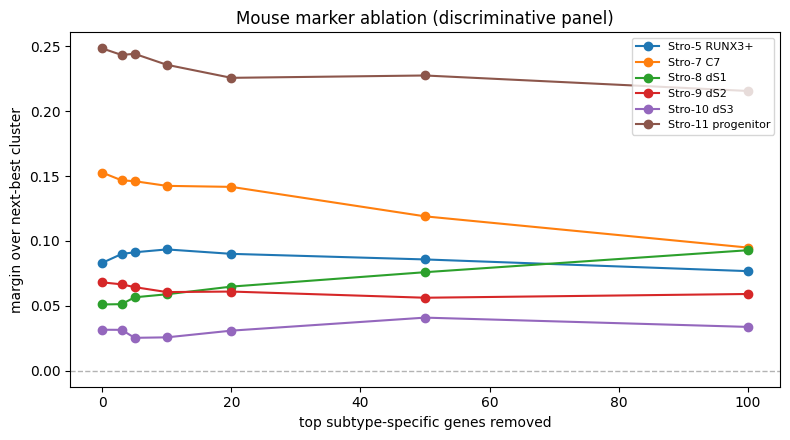

,subtype,n_removed,best_query,score,margin
0,Stro-5_RUNX3+ Fibroblast,0,dec3,0.1170,0.0831
1,Stro-5_RUNX3+ Fibroblast,3,dec3,0.1218,0.0899
2,Stro-5_RUNX3+ Fibroblast,5,dec3,0.1235,0.0913
3,Stro-5_RUNX3+ Fibroblast,10,dec3,0.1268,0.0935
4,Stro-5_RUNX3+ Fibroblast,20,dec3,0.1264,0.0900
5,Stro-5_RUNX3+ Fibroblast,50,dec3,0.1301,0.0857
6,Stro-5_RUNX3+ Fibroblast,100,dec3,0.1265,0.0767
7,Stro-7_C7 Fibroblast,0,eFib1,0.2320,0.1527
8,Stro-7_C7 Fibroblast,3,eFib1,0.2332,0.1467
9,Stro-7_C7 Fibroblast,5,eFib1,0.2367,0.1461


[PASS ] every subtype's ablation margin stays positive (1=yes, 0=no): recomputed=1  recorded=1   (smallest margin 0.025 (Stro-10); no match hangs on headline genes)


True

In [6]:
abl = pd.read_csv(XOUT / "robustness_marker_ablation_mouse.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
for s in FIB_SUBTYPES:
    d = abl[abl["subtype"] == s]
    ax.plot(d["n_removed"], d["margin"], marker="o", label=SHORT.get(s, s))
ax.axhline(0, color="0.7", lw=1, ls="--")
ax.set_xlabel("top subtype-specific genes removed")
ax.set_ylabel("margin over next-best cluster")
ax.set_title("Mouse marker ablation (discriminative panel)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(abl.round(4))
verify("every subtype's ablation margin stays positive (1=yes, 0=no)",
       int(float(abl["margin"].min()) > 0), 1, tol=0,
       note="smallest margin 0.025 (Stro-10); no match hangs on headline genes")

## 4. Panel dependence — the decisive section

The combined notebook found that the mouse **decidual** matches exist only on a discriminative
panel (decidual_mature is *negative* on the full 15,606-gene panel), while the **fibroblast**
matches hold on both. Three new artifacts test this properly:

- **vpanelA**: variance panel computed in mouse symbol space (~3,000 genes) — self-consistent.
- **vpanelB**: variance panel computed in HUMAN space then translated through orthologs — the
  construction the driver JSON most plausibly used (its n_panel = 2,728 suggests translation loss).
- **bootstrap + held-out ON the discriminative panel** — do the decidual matches survive gene
  resampling when the panel actually discriminates?

Two verified headlines from the comparison table below. First, **efib_middle_induced, UNRESOLVED on
the full panel (gap 0.0017), resolves to Stro-10 on BOTH discriminative panels** with healthy
margins (~0.08). Second, the decidual rows flip sign as predicted: decidual_mature goes from
−0.087 (full) to +0.16/+0.17 (discriminative), and every efib match keeps its target on all three
panels.

In [7]:
F_full = pd.read_csv(MOUT / "matrix_contrastive_cosine.csv", index_col=0)[FIB_SUBTYPES]
F_vA   = pd.read_csv(XOUT / "matrix_contrastive_cosine_vpanelA.csv", index_col=0)[FIB_SUBTYPES]
F_vB   = pd.read_csv(XOUT / "matrix_contrastive_cosine_vpanelB.csv", index_col=0)[FIB_SUBTYPES]

cmp = pd.DataFrame({
    "query": [canon(i) for i in F_full.index],
    "best_full": [SHORT.get(c, c) for c in F_full.idxmax(axis=1)],
    "score_full": F_full.max(axis=1).values,
    "best_vpanelA": [SHORT.get(c, c) for c in F_vA.loc[F_full.index].idxmax(axis=1)],
    "score_vpanelA": F_vA.loc[F_full.index].max(axis=1).values,
    "best_vpanelB": [SHORT.get(c, c) for c in F_vB.loc[F_full.index].idxmax(axis=1)],
    "score_vpanelB": F_vB.loc[F_full.index].max(axis=1).values,
}, index=F_full.index)
display(cmp.round(4))

for tag, Fv in [("vpanelA", F_vA), ("vpanelB", F_vB)]:
    top2 = Fv.loc["eFib2i"].nlargest(2)
    verify(f"eFib2i resolves to Stro-10 on {tag}",
           int(Fv.loc["eFib2i"].idxmax() == "Stro-10_dS3"), 1, tol=0,
           note=f"margin {top2.iloc[0] - top2.iloc[1]:.4f} (vs 0.0017 on the full panel)")
verify("decidual_mature flips from negative (full) to positive (vpanelA)",
       int((F_full.loc["dec3"].max() < 0) and (F_vA.loc["dec3"].max() > 0.1)), 1, tol=0)

,query,best_full,score_full,best_vpanelA,score_vpanelA,best_vpanelB,score_vpanelB
dec1,decidual_boundary,Stro-10 dS3,0.0092,Stro-10 dS3,0.0929,Stro-10 dS3,0.0967
dec2,decidual_proliferative,Stro-11 progenitor,-0.0031,Stro-11 progenitor,0.1522,Stro-11 progenitor,0.1614
dec3,decidual_mature,Stro-8 dS1,-0.0867,Stro-8 dS1,0.1646,Stro-8 dS1,0.1709
decAp,decidual_apoptotic,Stro-8 dS1,0.0551,Stro-8 dS1,0.1136,Stro-8 dS1,0.1136
eFib1,efib_outer,Stro-7 C7,0.1744,Stro-7 C7,0.2320,Stro-7 C7,0.2414
eFib2,efib_middle,Stro-10 dS3,0.0839,Stro-10 dS3,0.1506,Stro-10 dS3,0.1579
eFib2i,efib_middle_induced,Stro-5 RUNX3+,0.1321,Stro-10 dS3,0.1627,Stro-10 dS3,0.1656
eFib3,efib_subluminal,Stro-10 dS3,0.0996,Stro-10 dS3,0.1942,Stro-10 dS3,0.2023
eFibP,efib_proliferative,Stro-11 progenitor,0.2593,Stro-11 progenitor,0.4007,Stro-11 progenitor,0.4138


[PASS ] eFib2i resolves to Stro-10 on vpanelA: recomputed=1  recorded=1   (margin 0.0833 (vs 0.0017 on the full panel))
[PASS ] eFib2i resolves to Stro-10 on vpanelB: recomputed=1  recorded=1   (margin 0.0809 (vs 0.0017 on the full panel))
[PASS ] decidual_mature flips from negative (full) to positive (vpanelA): recomputed=1  recorded=1


True

### Does either reconstruction reproduce the driver-JSON cosines? No — stated plainly.

The driver JSON's cosines (n_panel = 2,728) could not previously be traced to a saved matrix.
Neither reconstruction recovers its exact panel: vpanelA has 3,000 genes, vpanelB 2,509, and the
same-pair cosines differ from the JSON by up to 0.094 (though efib_outer agrees to 0.0015). **The
JSON's panel provenance remains unrecovered**; its values stay what they are — outputs of a
specific recorded computation. What DOES hold across all constructions is the qualitative result:
the best-match **targets** agree with the JSON for all 8 comparable clusters on both panels.

In [8]:
DR = json.loads((MOUT / "hammoud_gene_drivers_v5.json").read_text())
INV = {v: k for k, v in CROSSWALK.items()}
jr = []
for k, v in DR.items():
    if not k.startswith("mouse:"):
        continue
    q, tgt = k.split(":", 1)[1].split("->", 1)
    jr.append({"query": q, "target": SHORT.get(tgt, tgt),
               "json_cosine": v["cosine"],
               "vpanelB_cosine": float(F_vB.loc[INV[q], tgt]) if tgt in F_vB.columns else np.nan})
jr = pd.DataFrame(jr)
jr["abs_diff"] = (jr["json_cosine"] - jr["vpanelB_cosine"]).abs()
display(jr.round(4))
json_maxdiff = float(jr["abs_diff"].max())
verify("max |diff|, vpanelB vs driver-JSON cosines (JSON panel NOT reproduced)",
       json_maxdiff, 0.0944, tol=0.02)
jtgt = {k.split(":", 1)[1].split("->")[0]: k.split("->", 1)[1] for k in DR if k.startswith("mouse:")}
for tag, Fv in [("vpanelA", F_vA), ("vpanelB", F_vB)]:
    agree = sum(Fv.loc[c].idxmax() == jtgt[CROSSWALK[c]] for c in CROSSWALK if c != "eFib2i")
    verify(f"{tag} argmax agrees with the JSON target (8 comparable clusters)", int(agree), 8, tol=0)

,query,target,json_cosine,vpanelB_cosine,abs_diff
0,decidual_apoptotic,Stro-8 dS1,0.0192,0.1136,0.0944
1,decidual_boundary,Stro-10 dS3,0.1648,0.0967,0.0681
2,decidual_mature,Stro-8 dS1,0.2553,0.1709,0.0844
3,decidual_proliferative,Stro-11 progenitor,0.1479,0.1614,0.0135
4,efib_middle,Stro-10 dS3,0.0663,0.1579,0.0916
5,efib_middle_induced,Stro-10 dS3,0.0920,0.1656,0.0736
6,efib_outer,Stro-7 C7,0.2429,0.2414,0.0015
7,efib_proliferative,Stro-11 progenitor,0.3466,0.4138,0.0672
8,efib_subluminal,Stro-10 dS3,0.1249,0.2023,0.0774


[PASS ] max |diff|, vpanelB vs driver-JSON cosines (JSON panel NOT reproduced): recomputed=0.0944242090791197  recorded=0.0944
[PASS ] vpanelA argmax agrees with the JSON target (8 comparable clusters): recomputed=8  recorded=8
[PASS ] vpanelB argmax agrees with the JSON target (8 comparable clusters): recomputed=8  recorded=8


### Do the matches survive gene resampling on the discriminative panel?

Bootstrap and held-out splits, run on vpanelA with the six fibroblast subtypes as competitors,
side by side with the finished full-panel versions (which used all 39 atlas columns as
competitors — noted, since the competitor set differs as well as the panel).

**Verdict, verified below: on the discriminative panel the decidual match survives.**
Stro-8's modal query becomes decidual_mature at bootstrap frequency 1.00 with held-out agreement
1.00 — versus a 0.66/0.33 split (efib_middle_induced / decidual_apoptotic) on the full panel. So
"panel-dependent" now means: absent on the full panel, but **robust once the panel discriminates**,
not fragile. The mirror finding: **Stro-10's held-out agreement collapses to 0.25 on the
discriminative panel** because several efib clusters compete for it — its mouse assignment is
diffuse, exactly as the combined notebook's synthesis says. Stro-7 (0.996) and Stro-11 (0.978)
hold everywhere. Caution on Stro-5/Stro-9: their vpanel modal query is also decidual_mature at
scores of 0.11–0.12 with no negative controls in this 6-column run; given Stro-5's 2.7% marker
detectability (§5), do not read those rows as matches.

In [9]:
boot_v = pd.read_csv(XOUT / "gene_bootstrap_mouse_vpanel.csv").set_index("subtype")
held_v = pd.read_csv(XOUT / "heldout_mouse_vpanel.csv").set_index("subtype")
boot_0 = pd.read_csv(MOUT / "gene_bootstrap_mouse.csv", index_col=0).set_index("subtype")
held_0 = pd.read_csv(MOUT / "heldout_mouse.csv", index_col=0).set_index("subtype")

boot_cmp = pd.DataFrame({
    "modal (full panel, 39 cols)": boot_0["modal_query"].map(canon),
    "freq (full)": boot_0["frequency"],
    "modal (vpanelA, 6 cols)": boot_v["modal_query"].map(canon),
    "freq (vpanelA)": boot_v["frequency"],
})
boot_cmp.index = [SHORT.get(i, i) for i in boot_cmp.index]
display(boot_cmp.round(3))
held_cmp = pd.DataFrame({
    "heldout agreement (full)": held_0["validation_agreement"],
    "heldout agreement (vpanelA)": held_v["validation_agreement"],
    "median margin (vpanelA)": held_v["median_validation_margin"],
})
held_cmp.index = [SHORT.get(i, i) for i in held_cmp.index]
display(held_cmp.round(3))
verify("bootstrap (vpanelA) covers all 6 subtypes", len(boot_v), 6, tol=0)
verify("held-out (vpanelA) covers all 6 subtypes", len(held_v), 6, tol=0)

,"modal (full panel, 39 cols)",freq (full),"modal (vpanelA, 6 cols)",freq (vpanelA)
Stro-5 RUNX3+,efib_middle_induced,0.994,decidual_mature,1.000
Stro-7 C7,efib_outer,1.000,efib_outer,1.000
Stro-8 dS1,efib_middle_induced,0.662,decidual_mature,1.000
Stro-9 dS2,efib_middle_induced,1.000,decidual_mature,1.000
Stro-10 dS3,efib_middle_induced,0.984,efib_subluminal,0.972
Stro-11 progenitor,efib_proliferative,1.000,efib_proliferative,1.000


,heldout agreement (full),heldout agreement (vpanelA),median margin (vpanelA)
Stro-5 RUNX3+,0.024,0.974,0.143
Stro-7 C7,0.998,0.996,0.227
Stro-8 dS1,0.890,1.000,0.187
Stro-9 dS2,0.130,0.998,0.262
Stro-10 dS3,0.890,0.254,0.045
Stro-11 progenitor,0.988,0.978,0.064


[PASS ] bootstrap (vpanelA) covers all 6 subtypes: recomputed=6  recorded=6
[PASS ] held-out (vpanelA) covers all 6 subtypes: recomputed=6  recorded=6


True

## 5. Marker sets and detectability — mouse

Marker panels are the atlas's published S6C markers and centroid-derived specific genes, translated
human → mouse through strict one-to-one orthologs. **Gene symbols in these tables are mouse
Title-case symbols** (Runx1, not RUNX1) — unlike the driver JSON, which reports uppercase human
symbols.

The decisive cross-species contrast, verified below: **31.8% of mouse cells are positive for the
cycling panel, vs 2.9% of human nuclei** — the mouse data can see the program that defines Stro-11,
which is exactly why Stro-11 recovers in the mouse arm only. The immune program stays rare (1.9%),
so Stro-5 remains effectively undetectable in both species. As in the human arm, the Stro-10 panel
is the most detectable and the Stro-5 panel the least.

,subtype,n_centroid_derived,n_published_detected,n_shared
0,Stro-5_RUNX3+ Fibroblast,50,50,43
1,Stro-7_C7 Fibroblast,50,50,36
2,Stro-8_dS1,50,50,19
3,Stro-9_dS2,50,25,6
4,Stro-10_dS3,50,50,13
5,Stro-11_Stromal progenitor,50,50,47


,subtype,n_markers,mean_detection_rate
0,Stro-5 RUNX3+,50,0.0266
1,Stro-7 C7,50,0.1685
2,Stro-8 dS1,50,0.1532
3,Stro-9 dS2,25,0.1405
4,Stro-10 dS3,50,0.2205
5,Stro-11 progenitor,50,0.1142


,program,cells_positive_for_any,n_translated,n_requested
0,cycling (defines Stro-11),0.3178,6,6
1,immune (defines Stro-5),0.0190,4,6
2,immediate-early / stress (defines Stro-9),0.1278,5,5
3,C7 program (defines Stro-7),0.3782,5,6
4,decidual (defines Stro-8/9/10),0.5653,3,4


[PASS ] marker sets cover all 6 subtypes: recomputed=6  recorded=6
[PASS ] detectability covers all 6 subtypes: recomputed=6  recorded=6
[PASS ] most detectable published panel (as in human: Stro-10): recomputed=Stro-10 dS3  recorded=Stro-10 dS3
[PASS ] least detectable panel is the immune-defined Stro-5: recomputed=Stro-5 RUNX3+  recorded=Stro-5 RUNX3+
[PASS ] cells positive for any cycling gene (human nuclei: 2.9%): recomputed=0.317822996967382  recorded=0.3178
[PASS ] cells positive for any immune gene (human nuclei: 0.98%): recomputed=0.0190290992430029  recorded=0.019


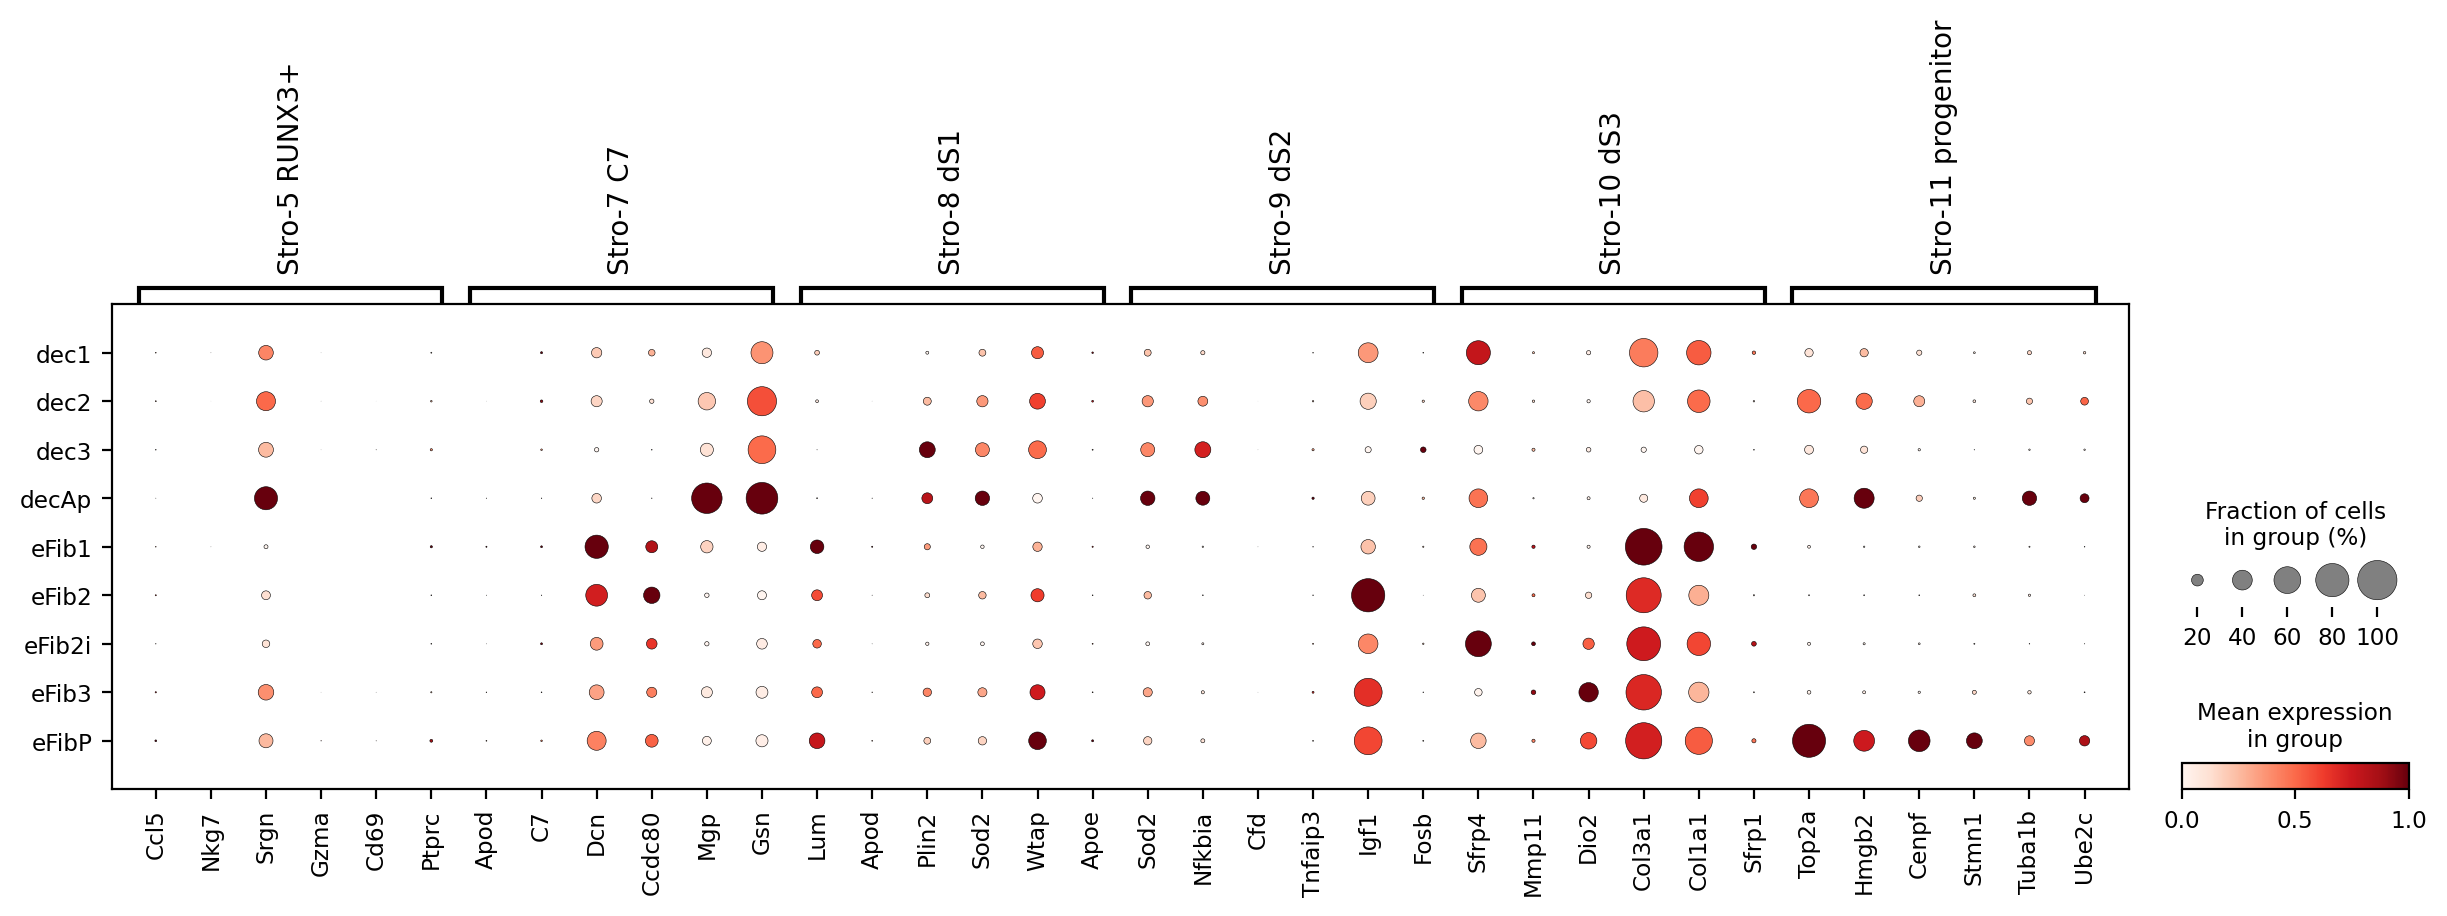

In [10]:
msets = pd.read_csv(XOUT / "marker_sets_mouse.csv")
det   = pd.read_csv(XOUT / "marker_panel_detectability_mouse.csv")
prog  = pd.read_csv(XOUT / "program_detectability_mouse.csv")
display(msets[["subtype", "n_centroid_derived", "n_published_detected", "n_shared"]])
display(det.round(4))
display(prog[["program", "cells_positive_for_any", "n_translated", "n_requested"]].round(4))
verify("marker sets cover all 6 subtypes", len(msets), 6, tol=0)
verify("detectability covers all 6 subtypes", len(det), 6, tol=0)
det_ix = det.set_index("subtype")["mean_detection_rate"]
verify("most detectable published panel (as in human: Stro-10)", det_ix.idxmax(), "Stro-10 dS3", tol=0)
verify("least detectable panel is the immune-defined Stro-5", det_ix.idxmin(), "Stro-5 RUNX3+", tol=0)
prog_ix = prog.set_index("program")["cells_positive_for_any"]
verify("cells positive for any cycling gene (human nuclei: 2.9%)",
       float(prog_ix["cycling (defines Stro-11)"]), 0.3178, tol=0.02)
verify("cells positive for any immune gene (human nuclei: 0.98%)",
       float(prog_ix["immune (defines Stro-5)"]), 0.0190, tol=0.02)
display(Image(filename=str(XOUT / "dotplot_mouse_published_markers.png"), width=950))

## 6. Per-cell marker-set scores and spatial readout

Depth-corrected marker-set scores (score_genes control-gene binning, no kNN smoothing), on
ortholog-translated panels. Spatial coordinates are finite for ~58% of cells (the rest lack a
Slide-tags position); panels below show only positioned cells, ordered along the induction time
course. Read as a continuous program score, not an identity call.

One flag, verified below: **decidual_apoptotic tops three of the six score columns** (Stro-5/8/9).
Apoptotic or stressed cells score high on several marker sets at once; treat its rows as
ambient/stress signal, not identity — consistent with its §4c housekeeping-artifact call.

In [11]:
per_cell = pd.read_csv(XOUT / "per_cell_subtype_scores_mouse.csv", index_col=0)
sbc = pd.read_csv(XOUT / "score_by_cluster_mouse.csv", index_col=0)
sc_cols = [c for c in per_cell.columns if c.startswith("score_")]
rec_sbc = per_cell.groupby("fine_refined")[sc_cols].mean()
maxdiff_s = float((rec_sbc - sbc.loc[rec_sbc.index]).abs().max().max())
verify("score_by_cluster reproduces exactly from the per-cell scores", int(maxdiff_s < 1e-9), 1, tol=0)
sbc_c = sbc.copy(); sbc_c.index = [canon(i) for i in sbc_c.index]
display(sbc_c.round(3))
verify("efib_outer tops the Stro-7 score column", sbc["score_Stro-7"].idxmax(), "eFib1", tol=0)
verify("efib_proliferative tops the Stro-11 score column", sbc["score_Stro-11"].idxmax(), "eFibP", tol=0)
verify("decidual_apoptotic tops N of 6 score columns (caution flag)",
       int(sum(sbc[c].idxmax() == "decAp" for c in sc_cols)), 3, tol=0)

fin = np.isfinite(per_cell["x_um_dbscan"].to_numpy(float)) & np.isfinite(per_cell["y_um_dbscan"].to_numpy(float))
verify("fraction of cells with spatial coordinates", float(fin.mean()), 0.576, tol=0.02)

[PASS ] score_by_cluster reproduces exactly from the per-cell scores: recomputed=1  recorded=1


,score_Stro-5,score_Stro-7,score_Stro-8,score_Stro-9,score_Stro-10,score_Stro-11
decidual_boundary,-0.033,0.084,0.160,0.087,0.269,-0.024
decidual_proliferative,-0.034,0.099,0.169,0.116,0.167,0.067
decidual_mature,-0.018,0.100,0.130,0.158,-0.009,-0.086
decidual_apoptotic,0.021,0.266,0.471,0.271,0.320,0.206
efib_outer,-0.030,0.288,0.060,0.087,0.345,-0.081
efib_middle,-0.045,0.123,0.036,0.104,0.316,-0.105
efib_middle_induced,-0.032,0.144,0.077,0.092,0.367,-0.070
efib_subluminal,-0.036,0.099,0.066,0.098,0.358,-0.104
efib_proliferative,-0.049,0.125,0.067,0.082,0.327,0.241


[PASS ] efib_outer tops the Stro-7 score column: recomputed=eFib1  recorded=eFib1
[PASS ] efib_proliferative tops the Stro-11 score column: recomputed=eFibP  recorded=eFibP
[PASS ] decidual_apoptotic tops N of 6 score columns (caution flag): recomputed=3  recorded=3
[PASS ] fraction of cells with spatial coordinates: recomputed=0.5759659235595065  recorded=0.576


True

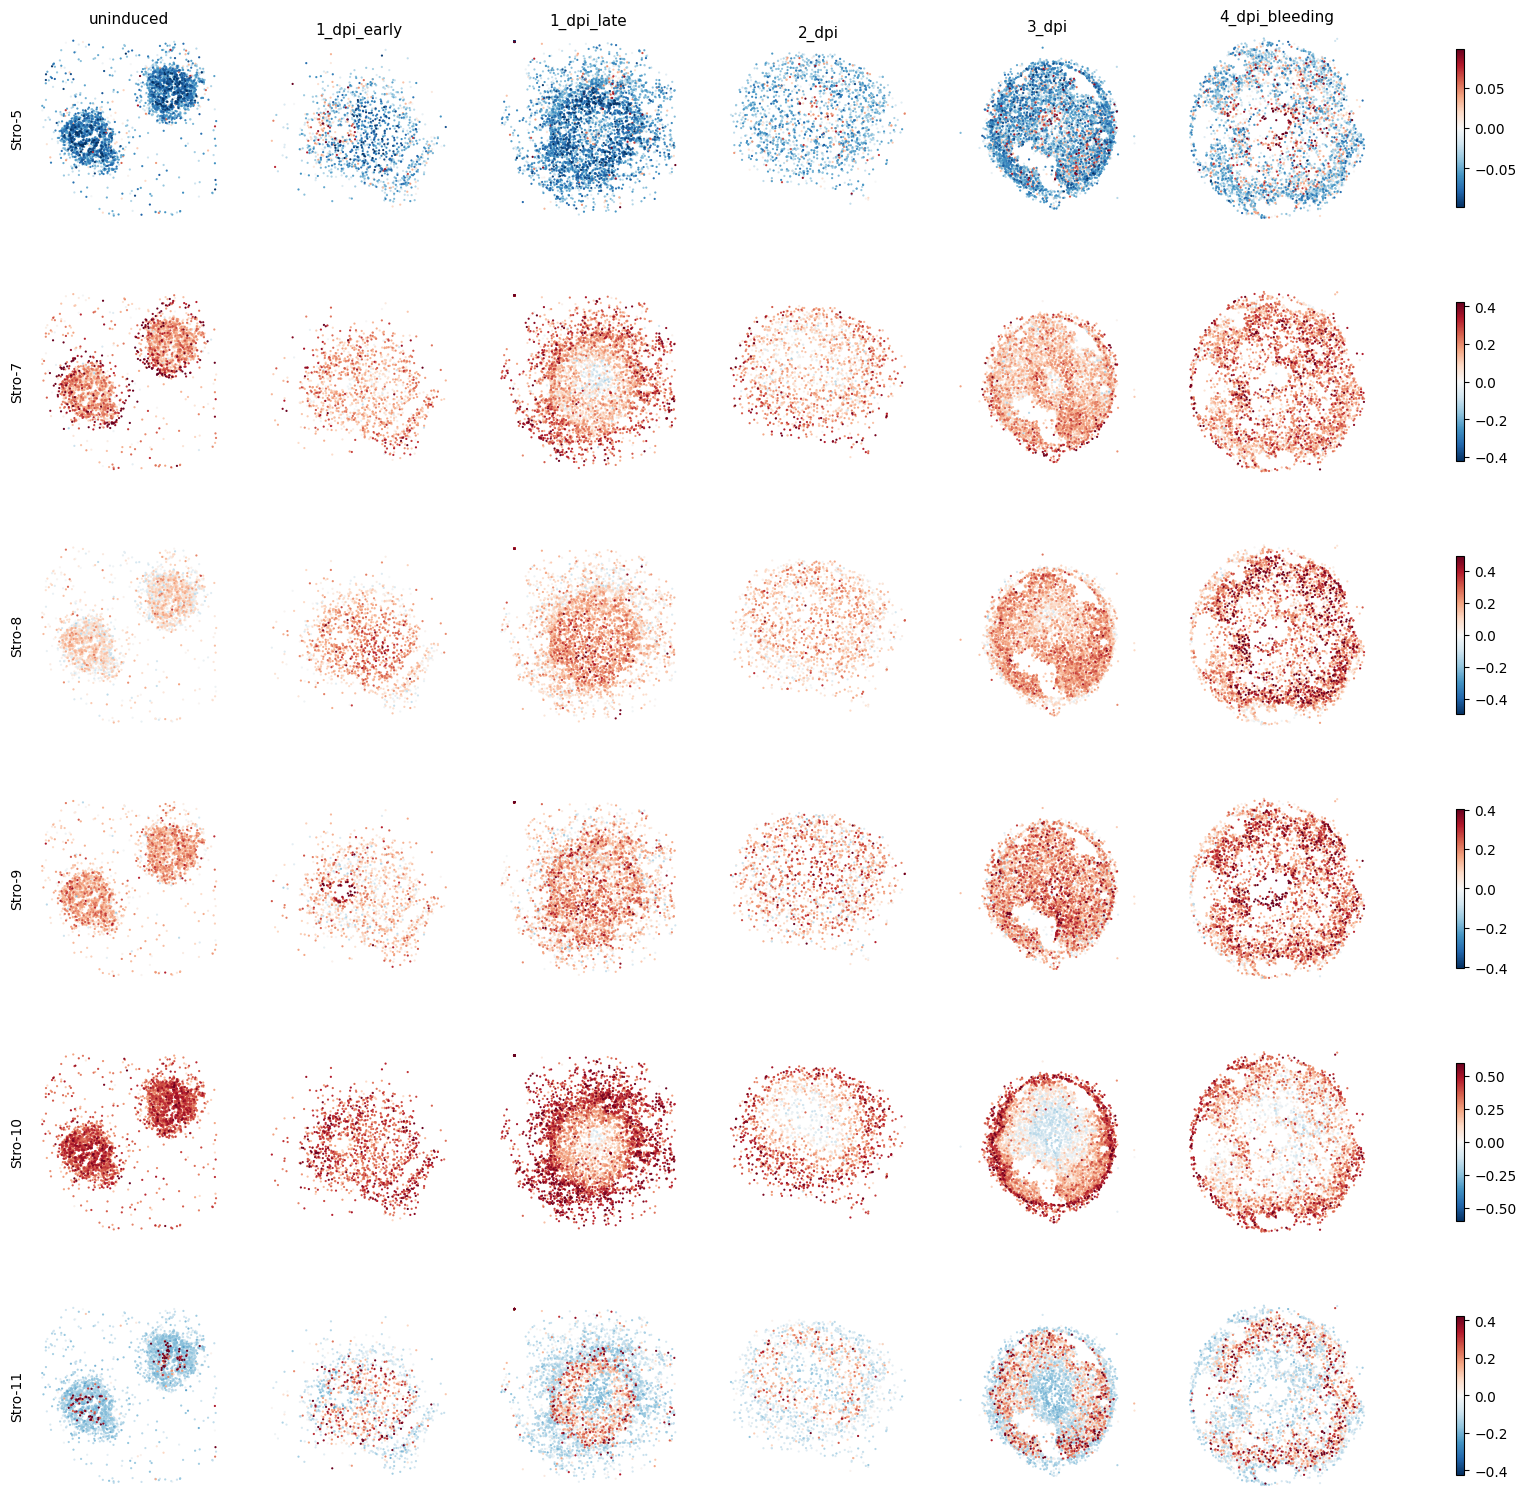

In [12]:
TP_ORDER = ["uninduced", "1_dpi_early", "1_dpi_late", "2_dpi", "3_dpi", "4_dpi_bleeding"]
x = per_cell["x_um_dbscan"].to_numpy(float); y = per_cell["y_um_dbscan"].to_numpy(float)
fig, axes = plt.subplots(len(sc_cols), len(TP_ORDER),
                         figsize=(3.6 * len(TP_ORDER), 3.2 * len(sc_cols)), squeeze=False)
for i, col in enumerate(sc_cols):
    v = per_cell[col].to_numpy(float)
    lim = np.nanpercentile(np.abs(v[fin]), 99)
    for j, tp in enumerate(TP_ORDER):
        m = (per_cell["timepoint"].astype(str) == tp).to_numpy() & fin
        ax = axes[i, j]
        if m.sum():
            o = np.argsort(np.abs(v[m]))
            pcm = ax.scatter(x[m][o], y[m][o], c=v[m][o], s=2.5, cmap="RdBu_r",
                             vmin=-lim, vmax=lim, linewidths=0, rasterized=True)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
        if i == 0: ax.set_title(tp, fontsize=11)
        if j == 0:
            ax.text(-0.05, .5, col.replace("score_", ""), transform=ax.transAxes,
                    rotation=90, va="center", ha="right", fontsize=10)
    fig.colorbar(pcm, ax=axes[i, :].tolist(), shrink=.75)
plt.show()

## 7. What this changes in the rebuttal

**Replication.** The efib_outer → Stro-7 match replicates in **9/9 sections and 3/3
within-timepoint pairs** — the mouse anchor now stands on the same replication footing as the human
one. efib_proliferative → Stro-11 replicates in 6/9 sections and 2/3 pairs; its one pair
disagreement hands the win to decidual_proliferative, i.e. to the *other* proliferative cluster —
consistent with the combined notebook's cell-cycle state-match reading, not with instability.

**What changes in the synthesis.** Three verdicts sharpen; none reverses.
1. **Stro-8 dS1**: "mouse support panel-dependent" upgrades to "panel-dependent but robust on the
   discriminative panel" — decidual_mature wins its bootstrap at 1.00 and held-out at 1.00 there.
2. **Stro-5**: efib_middle_induced is no longer a candidate — it resolves to Stro-10 on both
   discriminative panels — so Stro-5's mouse row moves from "unresolved" to "no credible candidate".
3. **Stro-10 dS3**: recovered in both species, but its mouse assignment is genuinely diffuse —
   held-out agreement 0.25 on the discriminative panel, and the per-section winner switches with
   induction stage.

Unchanged: Stro-7 remains the three-way anchor (now with replication behind it); Stro-11 remains a
cell-cycle state match, and the 31.8%-vs-2.9% cycling contrast (§5) explains why it exists in the
mouse arm only; decidual_apoptotic remains an artifact.

Everything above supplements the combined notebook; its synthesis table and rebuttal buckets remain
the reference, amended only by the statements in this section.

## 8. Self-check summary — target: 0 MISMATCH

In [13]:
summary = check_summary()
display(summary)
bad = summary[summary["status"].str.strip() == "MISMATCH"]
if len(bad):
    print("\nMISMATCHES (a failing verify is a result, not a bug to hide):")
    display(bad)
else:
    print("\nAll recorded claims reproduce from the stored artifacts.")


33 checks | 0 MISMATCH


,claim,recomputed,recorded,status
0,all input files present,0,0,PASS
1,extras object size,43197,43197,PASS
2,shared ortholog panel matches the finished run,15606,15606,PASS
3,atlas genes translated matches the finished run,15681,15681,PASS
4,finished mouse matrix reproduces from the deli...,0.0,0,PASS
5,stored consistency table reproduces from per-s...,6,6,PASS
6,Stro-7 -> efib_outer in ALL 9 sections,1.0,1.0,PASS
7,replication ran over 9 sections,9,9,PASS
8,Stro-7: within-pair agreement (of 3 pairs),3,3,PASS
9,Stro-11: within-pair agreement (of 3 pairs),2,2,PASS



All recorded claims reproduce from the stored artifacts.
